# Can covariates predict an Islamic win near the cutoff?
### OLS, Ridge and Lasso as a covariate-balance check for Meyersson (2014)

Meyersson's RD design compares municipalities where an Islamic party *barely won* the 1994 mayoral election with municipalities where it *barely lost*. The identifying assumption is **continuity at the cutoff**: apart from who won, municipalities just above and just below the cutoff are comparable, so close elections behave almost like a coin flip (Lee 2008; Week 5, *RDD*).

That assumption has a testable implication. If close elections are as good as random, characteristics fixed before the election should carry **no information about who won** once we zoom in on the cutoff. Across the full sample, by contrast, Islamic and secular municipalities differ markedly (Meyersson, Table I, col. 4).

We turn that implication into a prediction problem where we train OLS, Ridge and Lasso models to predict an Islamic win (`i94`) from pre-election covariates, in windows of shrinking width around the cutoff, and compare their out-of-sample performance with a benchmark that uses no covariates at all.

**How this connects to the course and paper**
- **Covariate smoothness** (RDD checklist, Week 5, item 3). Meyersson's version is Figure 3: one RD plot per covariate, plus a SUR joint test of all the jumps (p = 0.87). Here we ask a broader question: can *any combination* of covariates, including squares and interactions, predict treatment?
- **Propensity scores** (Week 3; R Labs, Block 3). Predicting treatment from pre-treatment covariates *is* estimating a propensity score. Under local randomization, the propensity score near the cutoff is flat: every municipality has the same probability of an Islamic win.
- **Bandwidth sensitivity** (RDD checklist, item 4). We repeat the exercise across several windows instead of relying on a single one.

## 1. Settings and data

In [1]:
# Random state used for sample splitting (train/test, cross-validation) and other RNGs
RANDOM_STATE = 1234

# Scoring metrics for cross-validation and evaluation
SCORERS = {'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'}

# Number of jobs to run in parallel 
NUM_JOBS = 4

In [2]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso

In [3]:

PATH = 'Data/regdata0.dta'

df = pd.read_stata(PATH)

print(f'Number of observations in the common sample: {len(df):,d}')

Number of observations in the common sample: 3,204


In [4]:
df.describe()

,vshr_islam2004,educpop_1520f,hischshr614m,hischshr614f,hischshr1520m,hischshr1520f,hvshr1520m,hvshr1520f,hischshr2125m,hischshr2125f,...,jhischshr1520m,jhivshr1520f,jhivshr1520m,rpopshr1520,rpopshr2125,rpopshr2630,rpopshr3164,nonagshr1530f,nonagshr1530m,anyc
count,3204.000000,3171.000000,3171.0,3171.0,3171.000000,3169.000000,3171.000000,3171.000000,3171.000000,3171.000000,...,3171.000000,3171.000000,3171.000000,3170.000000,3170.000000,3170.000000,3170.000000,3171.000000,3171.000000,2664.000000
mean,0.401157,1415.892463,0.0,0.0,0.187547,0.154314,0.055026,0.036612,0.254402,0.156655,...,0.342127,0.038943,0.059693,1.005211,1.003472,1.012048,1.018493,0.077408,0.347180,0.349474
std,0.163809,10966.754287,0.0,0.0,0.079215,0.096548,0.040064,0.033229,0.106916,0.101360,...,0.093595,0.034354,0.041409,0.169199,0.187898,0.153077,0.190477,0.079085,0.192571,0.476892
min,0.000000,20.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.027273,0.000000,0.000000,0.163994,0.131569,0.561221,0.546693,0.000000,0.021337,0.000000
25%,0.300042,151.000000,0.0,0.0,0.131102,0.074442,0.025641,0.010705,0.176573,0.074860,...,0.283784,0.012048,0.029330,0.921955,0.901802,0.920211,0.958349,0.022640,0.190034,0.000000
50%,0.416574,239.000000,0.0,0.0,0.181425,0.145455,0.046512,0.027701,0.245665,0.145299,...,0.348485,0.030303,0.051095,0.998353,1.005998,1.005937,0.996749,0.049304,0.308197,0.000000
75%,0.512954,474.500000,0.0,0.0,0.235669,0.221870,0.075741,0.053932,0.322402,0.226154,...,0.405500,0.056878,0.081173,1.095722,1.113109,1.088191,1.041152,0.102927,0.482749,1.000000
max,1.000000,516026.000000,0.0,0.0,0.683069,0.680377,0.341232,0.217001,0.661157,0.550157,...,0.734779,0.222529,0.343128,2.339105,1.891470,3.291018,8.029983,0.598901,0.976435,1.000000


## 2. Choosing the variables

The data set has 230 columns. We keep the target, the running variable, and a set of covariates built around the balance covariates in Meyersson's Figure 3.

One choice matters for the logic of the test: we use **1990 census values** rather than 2000 values. A balance check only makes sense for variables determined *before* treatment. Values from the 2000 census could themselves be affected by who became mayor in 1994, which would make them bad controls (Week 3). Using 1990 values mirrors Meyersson's robustness check with 1990 census controls (Table IV, col. 2).

We also add a few covariates the paper uses in its other robustness checks in Table IV: the 1989 Islamic-mayor dummy (col. 6), whether the secular rival was left-wing (cols. 3–4), and the 1990 shares married and women employed (col. 2).

**Target and running variable**

| Variable | Description |
|---|---|
| `i94` | 1 if an Islamic party (mainly Refah) won the 1994 mayoral election, 0 otherwise. This is the treatment in the paper. |
| `vi1` | Islamic win margin in 1994: the running variable, with the cutoff at 0. |

`vi1` is only used to define the windows, never as a feature. In a sharp RD, treatment is a deterministic function of the running variable, $m_i = 1\{x_i \ge 0\}$, so including it would let the models predict `i94` perfectly and tell us nothing about the covariates.

**Covariates**

| Variable | Description | Where it appears in the paper |
|---|---|---|
| `partycount` | Number of parties receiving votes, 1994 | Figure 3 |
| `anyc` | Municipality is any type of centre (binary) | Figure 3 (centre dummy) |
| `c90lpop` | Log population, 1990 | Figure 3; 1990 version in Table IV, col. 2 |
| `c90ageshr19` | Share of the population below 19, 1990 | Figure 3; 1990 version in Table IV, col. 2 |
| `c90ageshr60` | Share of the population above 60, 1990 | Figure 3; 1990 version in Table IV, col. 2 |
| `c90sexr` | Gender ratio, 1990 | Figure 3; 1990 version in Table IV, col. 2 |
| `i89` | Islamic mayor elected in 1989 (binary) | Table IV, col. 6 |
| `islamleft1994` | The secular rival in 1994 was a left-wing party (binary) | Table IV, cols. 3–4 |
| `c90mrf` | Share married, 1990 | Table IV, col. 2 |
| `c90empf` | Share of women employed, 1990 | Table IV, col. 2 |

*Notes*
- `partycount` and `islamleft1994` are measured in the 1994 election itself rather than before it. They cannot be affected by who governs after 1994, but they come from the same election that decides treatment, which is worth keeping in mind when interpreting them.
- **Left out: `vshr_islam1994`** (Islamic vote share, 1994). The paper includes it in Figure 3, but it is mechanically tied to the win margin, especially across the full range of `vi1`. Including it would let the models predict treatment partly *through the running variable* rather than through municipality characteristics.

In [5]:
ids = ["province_pre", "belediye_pre", "pcode", "province_post"]
running = ["i94", 'vi1']
covariates = [ "partycount", "anyc", "c90lpop", "c90ageshr19",
              "c90ageshr60", "c90sexr", "i89", "islamleft1994", "c90mrf", "c90empf"]

df = df[ids + running + covariates]

df.describe()

,pcode,i94,vi1,partycount,anyc,c90lpop,c90ageshr19,c90ageshr60,c90sexr,i89,islamleft1994,c90mrf,c90empf
count,3204.000000,2662.000000,2664.000000,2664.000000,2664.000000,1872.000000,1872.000000,1872.000000,1872.000000,1916.000000,2664.000000,1872.000000,1872.000000
mean,34.341137,0.123216,-0.278167,5.586336,0.349474,8.694899,0.449343,0.077836,1.074371,0.036534,0.210961,0.619947,0.002563
std,18.873121,0.328745,0.222157,2.251727,0.476892,1.120688,0.081307,0.031280,0.207176,0.187666,0.408065,0.049900,0.005091
min,1.000000,0.000000,-1.000000,1.000000,0.000000,6.687109,0.188234,0.015141,0.709607,0.000000,0.000000,0.433888,0.000000
25%,19.000000,0.000000,-0.459543,4.000000,0.000000,7.927144,0.391336,0.054471,0.977113,0.000000,0.000000,0.589180,0.000000
50%,36.500000,0.000000,-0.309803,5.000000,0.000000,8.352791,0.445910,0.072581,1.031011,0.000000,0.000000,0.625000,0.000000
75%,48.250000,0.000000,-0.105798,7.000000,1.000000,9.135672,0.502990,0.096255,1.101460,0.000000,0.000000,0.654401,0.003141
max,67.000000,1.000000,0.990510,14.000000,1.000000,14.099393,0.699875,0.224877,3.324812,1.000000,1.000000,0.787554,0.062633


## 3. Cleaning

**Missing values.** We drop every row with a missing value in any of the kept columns. The sample falls from 3,204 to 1,784 rows. The 540 rows missing `anyc` match the 540 rows without 1994 election data; the largest substantive loss is 794 municipalities without 1990 census age shares.

Our sample is therefore smaller than the paper's 2,629 municipalities, so the window sizes below are not directly comparable with the observation counts in Meyersson's tables.

In [6]:
columns = sorted(df.columns)
for column in columns:
    n_missing = df[column].isna().sum()
    if n_missing > 0:
        print(f'Dropping {n_missing:3,d} rows with missing values in {column}')
        df = df.dropna(subset=[column]).copy()

Dropping 540 rows with missing values in anyc
Dropping 794 rows with missing values in c90ageshr19
Dropping  86 rows with missing values in i89


In [7]:
df.describe()

,pcode,i94,vi1,partycount,anyc,c90lpop,c90ageshr19,c90ageshr60,c90sexr,i89,islamleft1994,c90mrf,c90empf
count,1784.000000,1784.000000,1784.000000,1784.000000,1784.000000,1784.000000,1784.000000,1784.000000,1784.000000,1784.000000,1784.000000,1784.000000,1784.000000
mean,33.676010,0.116031,-0.273476,5.811659,0.455717,8.724327,0.446778,0.078265,1.077003,0.034193,0.218610,0.621053,0.002639
std,18.787075,0.320351,0.213005,2.161814,0.498172,1.129216,0.079631,0.031332,0.209490,0.181773,0.413419,0.049332,0.005169
min,1.000000,0.000000,-0.968760,2.000000,0.000000,6.959399,0.188234,0.015141,0.709607,0.000000,0.000000,0.433888,0.000000
25%,18.000000,0.000000,-0.442442,4.000000,0.000000,7.942629,0.389540,0.054757,0.977968,0.000000,0.000000,0.590395,0.000000
50%,35.000000,0.000000,-0.302638,5.000000,0.000000,8.385260,0.443725,0.073018,1.031792,0.000000,0.000000,0.625668,0.000000
75%,48.000000,0.000000,-0.115773,7.000000,1.000000,9.209941,0.498975,0.096780,1.103335,0.000000,0.000000,0.654832,0.003315
max,67.000000,1.000000,0.593436,14.000000,1.000000,14.099393,0.673235,0.224877,3.324812,1.000000,1.000000,0.787554,0.062633


**Group the variables by type:** identifiers, continuous covariates and binary covariates. The features are the continuous and binary covariates together.

In [8]:
non_numerical = ['belediye_pre', 'province_pre', 'province_post', 'pcode']
non_binary = ['partycount', 'c90lpop', 'c90ageshr19', 'c90ageshr60', 'c90sexr', 'c90mrf', 'c90empf']
binary = ['anyc', 'i89', 'islamleft1994']

target = ['i94']
running_var = ['vi1']

features = non_binary + binary

### Distributions of the covariates

A helper that draws one histogram per column, arranged in a grid.

In [9]:

def plot_histograms(df_data, title=None, max_cols=3, ylabel='Count'):
    """
    Plot a histogram for every column in a DataFrame, arranged in a grid.

    Parameters
    ----------
    df_data : DataFrame
        Numeric columns to plot
    title : str or None
        Optional title for the entire figure
    max_cols : int
        Maximum number of plots per row
    ylabel : str
        Label for the y-axis
    """
    nvars = df_data.shape[1]
    ncols = min(nvars, max_cols)
    nrows = math.ceil(nvars / ncols)
    figsize = (3 * ncols, 2.8 * nrows)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=figsize, layout='constrained', squeeze=False
    )
    axes = axes.flatten()

    for ax, col in zip(axes, df_data.columns):
        ax.hist(df_data[col], bins=40, color='steelblue', ec='white', lw=0.4)
        ax.set_xlabel(col)
        ax.set_ylabel(ylabel)

    # Hide any leftover empty panels in the last row
    for ax in axes[nvars:]:
        ax.set_visible(False)

    if title is not None:
        fig.suptitle(title)

The histograms show the distribution of each covariate and make outliers easy to spot. `c90sexr` (the gender ratio) has a handful of extreme values.

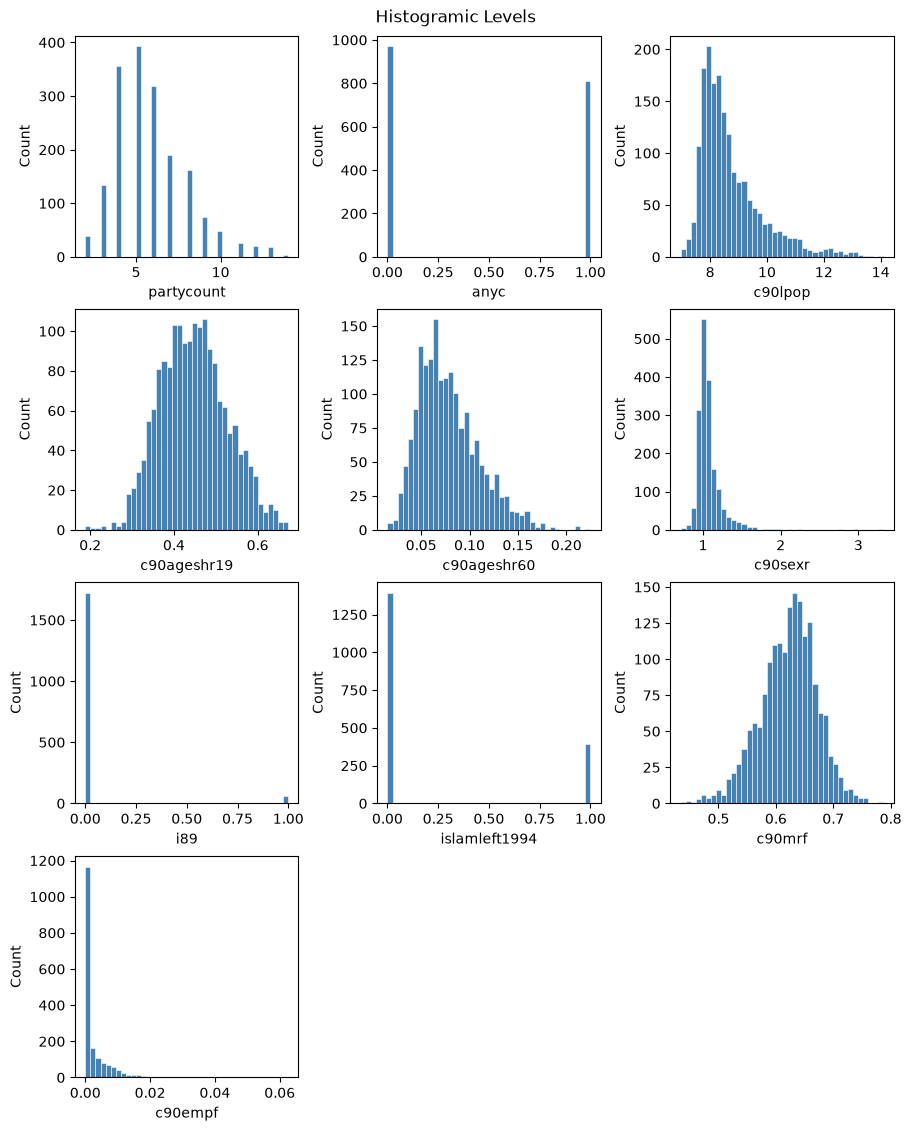

In [10]:
df_features = df.drop(columns=non_numerical + target + running_var)

plot_histograms(df_features, title='Histogramic Levels')

**Outliers in the gender ratio.** A gender ratio above 2 (more than two men per woman) is implausible for an ordinary municipal population and most likely reflects data errors or very unusual populations. We drop the 15 rows above 2, leaving 1,769 municipalities. This is a judgment call, so it is worth checking that the results do not hinge on it.

In [11]:
# Drop extreme outliers for sex ratio in 1990
drop = df['c90sexr'] > 2
print(f'Dropping {drop.sum():3,d} rows with a gender ratio above 2')
df = df[~drop].copy()
print(f'We are left with {len(df)} observations in the data frame')

Dropping  15 rows with a gender ratio above 2
We are left with 1769 observations in the data frame


## 4. Windows around the cutoff

Every model is fitted in five samples. Each is a symmetric window $|vi1| < h$ around the cutoff, the same $(c-h,\, c+h)$ window as in the paper's equation (1).

| Window | $h$ | How it is chosen |
|---|---|---|
| `full` | 1 | The entire sample, no restriction |
| `h` | 0.24 | Meyersson's Imbens–Kalyanaraman bandwidth for female high-school completion (Table II) |
| `h/2` | 0.12 | Half of that, as in Table II, col. 5 |
| `n200` | ≈ 0.059 | The window that holds exactly 200 municipalities |
| `n100` | ≈ 0.030 | The window that holds exactly 100 municipalities |

The paper's $\hat h$ was chosen for an outcome regression, not for this prediction problem, so here it is only a reference point. Shrinking the window is the course's bandwidth-sensitivity logic (RDD checklist, item 4; the $h/2$, $h$, $2h$ trio in the R Labs). The trade-off: narrower windows are closer to "as good as random", but smaller, so the cross-validated scores become noisier.

In [12]:

h_paper = 0.24  # IK bandwidth for female high school, Table II

In [13]:
# Distance to the cutoff
df['dist'] = df[running_var].abs()

In [14]:
# Midpoint between the n-th and (n+1)-th closest -> exactly n rows with dist < h
def h_for_n(data, n):
    s = np.sort(data['dist'].to_numpy())
    return (s[n - 1] + s[n]) / 2

In [15]:
h_200 = h_for_n(df, 200)

h_100 = h_for_n(df, 100)

print(f'We now have two additional win margin bandwiths with 200 obervations ({100*(h_200):5f}%), and with 100 observations ({100*(h_100):5f}%)')

We now have two additional win margin bandwiths with 200 obervations (5.889308%), and with 100 observations (3.007574%)


In [16]:
bandwidths = [1, h_paper, h_paper/2, h_200, h_100]

print('All the bandwidhts are as follows:')
for i in bandwidths:
    print(i)

All the bandwidhts are as follows:
1
0.24
0.12
0.05889308452606201
0.030075743794441223


**One data frame per window**, keeping the rows with `dist` below each $h$.

In [17]:
df_full = df

df_h_paper = df[df["dist"] < h_paper].copy()
print(f'Data frame with bandwidth {h_paper} created. Number of observation: {len(df_h_paper)}')

df_half_h_paper = df[df["dist"] < (h_paper/2)].copy()
print(f'Data frame with bandwidth {h_paper/2} created. Number of observation: {len(df_half_h_paper)}')

df_h_200 = df[df["dist"] < h_200].copy()
print(f'Data frame with bandwidth {h_200} created. Number of observation: {len(df_h_200)}')

df_h_100 = df[df["dist"] < h_100].copy()
print(f'Data frame with bandwidth {h_100} created. Number of observation: {len(df_h_100)}')

Data frame with bandwidth 0.24 created. Number of observation: 694
Data frame with bandwidth 0.12 created. Number of observation: 383
Data frame with bandwidth 0.05889308452606201 created. Number of observation: 200
Data frame with bandwidth 0.030075743794441223 created. Number of observation: 100


**Features and target for each window**

In [18]:
X_full, y_full = df_full[features], df_full['i94']
X_h_paper, y_h_paper = df_h_paper[features], df_h_paper[target]
X_half_h_paper, y_half_h_paper = df_half_h_paper[features], df_half_h_paper[target]
X_h_200, y_h_200 = df_h_200[features], df_h_200[target]
X_h_100, y_h_100 = df_h_100[features], df_h_100[target]

In [19]:
bandwidths = [
    ('full', X_full, y_full),
    ('h', X_h_paper, y_h_paper),
    ('h/2', X_half_h_paper, y_half_h_paper),
    ('n200', X_h_200, y_h_200),
    ('n100', X_h_100, y_h_100),
]

## 5. Models

### The pipeline

`make_model` chains four steps: standardize the raw features → expand them into polynomial terms (squares and interactions) → standardize again → fit the estimator.

The first scaling keeps the polynomial terms on comparable magnitudes. The second matters for Ridge and Lasso: their penalties depend on the scale of each coefficient, so without it some terms would be penalized more than others for arbitrary reasons. The polynomial degree is tuned by cross-validation.

In [20]:


def make_model(estimator):
    """
    Build a polynomial regression pipeline.

    Parameters
    ----------
    estimator : object
        Regression estimator used after preprocessing

    Returns
    -------
    Unfitted pipeline containing preprocessing and regression
    """
    pipe = Pipeline(
        [
            ('input_scale', StandardScaler()),
            ('poly', PolynomialFeatures(include_bias=False)),
            ('scale', StandardScaler()),
            ('model', estimator),
        ]
    )
    return pipe

### How fast the feature set grows

With 10 covariates, degree 2 gives 65 terms and degree 3 gives 285. We only search degrees 1 and 2. In the `n100` window each training fold has 80 observations, so a degree-2 OLS model already has nearly as many parameters as observations. This is where Ridge and Lasso earn their place: they can use the flexible expansion while shrinking the terms that do not help.

In [21]:
for degree in [1, 2, 3]:
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    poly.fit(X_full)
    print(f'Degree {degree}: {poly.n_output_features_:3d} polynomial columns')

Degree 1:  10 polynomial columns
Degree 2:  65 polynomial columns
Degree 3: 285 polynomial columns


### Cross-validation set-up

5-fold cross-validation with shuffled folds and a fixed seed, so every model sees the same splits. A model's score is its RMSE on the held-out folds.

Because `i94` is binary, OLS here is a **linear probability model**: the predictions are estimated probabilities of an Islamic win (and can fall outside [0, 1]). The RMSE is then the square root of the Brier score.

**A benchmark for reading the RMSE.** Predicting the window's share of Islamic wins, $\bar p$, for every municipality (an intercept-only model, i.e. a flat propensity score) gives an RMSE equal to the standard deviation of `i94` in that window, $\sqrt{\bar p(1-\bar p)}$. A model only carries information about treatment if its CV RMSE is clearly below this benchmark. The benchmark differs across windows because the share of Islamic wins differs, so compare each RMSE with its own window's benchmark rather than across windows.

In [22]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

degrees = [1, 2, 3]

### OLS: tuning the polynomial degree

For each window, search over degree ∈ {1, 2}, refit the best model on the whole window, and report its degree and CV RMSE.

In [23]:
# Define the GridSearchCV object for all the different OLSs
def make_ols_search(X, y):
    """
    Build, fit and return an OLS grid search over the polynomial degree.

    Returns
    -------
    search : GridSearchCV
        Fitted grid search
    degree_ols : int
        Selected polynomial degree
    rmse_ols : float
        Cross-validated RMSE of the selected model
    r2_ols : float
        Cross-validated R² of the selected model
    r2_sd_ols : float
        Standard deviation of R² across folds
    """
    search = GridSearchCV(
        make_model(LinearRegression()),
        param_grid={'poly__degree': degrees},
        cv=cv,
        scoring=SCORERS,
        refit='rmse',
        return_train_score=True,
        n_jobs=NUM_JOBS,
    )
    search.fit(X, y)

    best = search.best_index_
    degree_ols = search.best_params_['poly__degree']
    rmse_ols = -search.best_score_
    r2_ols = search.cv_results_['mean_test_r2'][best]
    r2_sd_ols = search.cv_results_['std_test_r2'][best]

    return search, degree_ols, rmse_ols, r2_ols, r2_sd_ols

In [24]:
# Store the selected results of every search for the summary table at the end
results = {}

for name, i, j in bandwidths:
    search, degree_ols, rmse_ols, r2_ols, r2_sd_ols = make_ols_search(i, j)
    results[(name, 'OLS')] = dict(n=len(j), degree=degree_ols, penalty=np.nan,
                                  rmse=rmse_ols, r2=r2_ols, nonzero_terms='-')
    print(f'With bandwidth {name}, the optimal OLS gives polynomial degree {degree_ols}, RMSE {rmse_ols:.4f} and R² {r2_ols:.4f} (sd {r2_sd_ols:.4f})')

With bandwidth full, the optimal OLS gives polynomial degree 1, RMSE 0.3023 and R² 0.1055 (sd 0.0549)
With bandwidth h, the optimal OLS gives polynomial degree 1, RMSE 0.4371 and R² 0.0242 (sd 0.0329)
With bandwidth h/2, the optimal OLS gives polynomial degree 1, RMSE 0.4881 and R² -0.0467 (sd 0.0286)
With bandwidth n200, the optimal OLS gives polynomial degree 1, RMSE 0.5205 and R² -0.1354 (sd 0.0825)


With bandwidth n100, the optimal OLS gives polynomial degree 1, RMSE 0.5332 and R² -0.1835 (sd 0.2491)


### Ridge

The same search, plus the penalty $\lambda$ (`alpha` in scikit-learn) over 500 log-spaced values from $10^{-2}$ to $10^{6}$. A large $\lambda$ shrinks all coefficients towards zero, so the model approaches the intercept-only benchmark.

If the selected $\lambda$ sits at the edge of the grid (as in the `n200` window, $\lambda = 10^6$), cross-validation prefers even more shrinkage than the grid allows. Extend the grid before reading anything into the exact value.

In [25]:
ridge_lambdas = np.logspace(0, 6, num=500)

In [26]:
def make_ridge_search(X, y):
    """
    Build, fit and return a Ridge grid search over polynomial degree and lambda.

    Returns
    -------
    search : GridSearchCV
        Fitted grid search
    degree_ridge : int
        Selected polynomial degree
    lambda_ridge : float
        Selected regularization strength
    rmse_ridge : float
        Cross-validated RMSE of the selected model
    r2_ridge : float
        Cross-validated R² of the selected model
    r2_sd_ridge : float
        Standard deviation of R² across folds
    """
    search = GridSearchCV(
        make_model(Ridge()),
        param_grid={'poly__degree': degrees, 'model__alpha': ridge_lambdas},
        cv=cv,
        scoring=SCORERS,
        refit='rmse',
        return_train_score=True,
        n_jobs=NUM_JOBS,
    )
    search.fit(X, y)

    best = search.best_index_
    degree_ridge = search.best_params_['poly__degree']
    lambda_ridge = search.best_params_['model__alpha']
    rmse_ridge = -search.best_score_
    r2_ridge = search.cv_results_['mean_test_r2'][best]
    r2_sd_ridge = search.cv_results_['std_test_r2'][best]

    return search, degree_ridge, lambda_ridge, rmse_ridge, r2_ridge, r2_sd_ridge

In [27]:
for name, i, j in bandwidths:
    search, degree_ridge, lambda_ridge, rmse_ridge, r2_ridge, r2_sd_ridge = make_ridge_search(i, j)
    results[(name, 'Ridge')] = dict(n=len(j), degree=degree_ridge, penalty=lambda_ridge,
                                    rmse=rmse_ridge, r2=r2_ridge, nonzero_terms='-')
    print(f'With bandwidth {name}, the optimal Ridge gives polynomial degree {degree_ridge}, lambda {lambda_ridge:.4g}, RMSE {rmse_ridge:.4f} and R² {r2_ridge:.4f} (sd {r2_sd_ridge:.4f})')

With bandwidth full, the optimal Ridge gives polynomial degree 2, lambda 616, RMSE 0.3003 and R² 0.1176 (sd 0.0394)


With bandwidth h, the optimal Ridge gives polynomial degree 1, lambda 113.8, RMSE 0.4360 and R² 0.0293 (sd 0.0238)


With bandwidth h/2, the optimal Ridge gives polynomial degree 2, lambda 3725, RMSE 0.4794 and R² -0.0100 (sd 0.0189)


With bandwidth n200, the optimal Ridge gives polynomial degree 1, lambda 1e+06, RMSE 0.4971 and R² -0.0350 (sd 0.0422)


With bandwidth n100, the optimal Ridge gives polynomial degree 1, lambda 247.1, RMSE 0.4992 and R² -0.0267 (sd 0.0546)


### Lasso

The same search, with the penalty $\alpha$ over 500 log-spaced values from $10^{-4}$ to $10^{2}$. Lasso can set coefficients exactly to zero, so we also count the non-zero coefficients in the refitted model. **Zero non-zero coefficients means cross-validation chose the intercept-only model**: every municipality in the window gets the same predicted probability.

The `ConvergenceWarning`s mostly reflect the very strict tolerance (`tol=1e-7`). Raising `max_iter` or loosening `tol` would remove them.

In [28]:
lasso_model = Lasso(
    max_iter=100_000,
    tol=1e-4,
    precompute=True,
    selection='random',
    random_state=RANDOM_STATE,
)

lasso_alphas = np.logspace(-3, 2, num=500)

In [29]:
def make_lasso_search(X, y):
    """
    Build, fit and return a Lasso grid search over polynomial degree and alpha.

    Returns
    -------
    search : GridSearchCV
        Fitted grid search
    degree_lasso : int
        Selected polynomial degree
    alpha_lasso : float
        Selected regularization strength
    rmse_lasso : float
        Cross-validated RMSE of the selected model
    r2_lasso : float
        Cross-validated R² of the selected model
    r2_sd_lasso : float
        Standard deviation of R² across folds
    n_nonzero : int
        Number of nonzero coefficients in the refitted model
    n_terms : int
        Total number of polynomial terms in the refitted model
    """
    search = GridSearchCV(
        make_model(lasso_model),
        param_grid={'poly__degree': degrees, 'model__alpha': lasso_alphas},
        cv=cv,
        scoring=SCORERS,
        refit='rmse',
        return_train_score=True,
        n_jobs=NUM_JOBS,
    )
    search.fit(X, y)

    best = search.best_index_
    degree_lasso = search.best_params_['poly__degree']
    alpha_lasso = search.best_params_['model__alpha']
    rmse_lasso = -search.best_score_
    r2_lasso = search.cv_results_['mean_test_r2'][best]
    r2_sd_lasso = search.cv_results_['std_test_r2'][best]

    lasso_best = search.best_estimator_.named_steps['model']
    n_nonzero = np.count_nonzero(np.abs(lasso_best.coef_) > 1e-8)
    n_terms = search.best_estimator_.named_steps['poly'].n_output_features_

    return search, degree_lasso, alpha_lasso, rmse_lasso, r2_lasso, r2_sd_lasso, n_nonzero, n_terms

In [30]:
for name, i, j in bandwidths:
    search, degree_lasso, alpha_lasso, rmse_lasso, r2_lasso, r2_sd_lasso, n_nonzero, n_terms = make_lasso_search(i, j)
    results[(name, 'Lasso')] = dict(n=len(j), degree=degree_lasso, penalty=alpha_lasso,
                                    rmse=rmse_lasso, r2=r2_lasso, nonzero_terms=f'{n_nonzero}/{n_terms}')
    print(f'With bandwidth {name}, the optimal Lasso gives polynomial degree {degree_lasso}, alpha {alpha_lasso:.4g}, RMSE {rmse_lasso:.4f}, R² {r2_lasso:.4f} (sd {r2_sd_lasso:.4f}) and {n_nonzero}/{n_terms} non-zero covariates')

With bandwidth full, the optimal Lasso gives polynomial degree 2, alpha 0.01102, RMSE 0.3012, R² 0.1123 (sd 0.0387) and 16/65 non-zero covariates


With bandwidth h, the optimal Lasso gives polynomial degree 2, alpha 0.02054, RMSE 0.4355, R² 0.0318 (sd 0.0140) and 16/65 non-zero covariates


With bandwidth h/2, the optimal Lasso gives polynomial degree 1, alpha 0.07477, RMSE 0.4802, R² -0.0133 (sd 0.0133) and 0/10 non-zero covariates


With bandwidth n200, the optimal Lasso gives polynomial degree 1, alpha 0.1033, RMSE 0.4971, R² -0.0350 (sd 0.0422) and 0/10 non-zero covariates


With bandwidth n100, the optimal Lasso gives polynomial degree 3, alpha 0.1271, RMSE 0.5030, R² -0.0420 (sd 0.0379) and 1/285 non-zero covariates


### Summary of the selected parameters

Cross-validated results for the selected model of each type in each window. λ/α is the penalty (`alpha` in scikit-learn); non-zero terms are reported for Lasso only.

| Window | Model | Degree | λ / α | CV RMSE | CV R² (sd) | Non-zero / terms |
|---|---|---|---|---|---|---|
| full (h = 1, n = 1,769) | OLS | 1 | – | 0.3023 | 0.1055 (0.0549) | – |
| full | Ridge | 2 | 616 | 0.3003 | 0.1176 (0.0394) | – |
| full | Lasso | 2 | 0.01102 | 0.3012 | 0.1123 (0.0387) | 16/65 |
| h (h = 0.24, n = 694) | OLS | 1 | – | 0.4371 | 0.0242 (0.0329) | – |
| h | Ridge | 1 | 113.8 | 0.4360 | 0.0293 (0.0238) | – |
| h | Lasso | 2 | 0.02054 | 0.4355 | 0.0318 (0.0140) | 16/65 |
| h/2 (h = 0.12, n = 383) | OLS | 1 | – | 0.4881 | -0.0467 (0.0286) | – |
| h/2 | Ridge | 2 | 3725 | 0.4794 | -0.0100 (0.0189) | – |
| h/2 | Lasso | 1 | 0.07477 | 0.4802 | -0.0133 (0.0133) | 0/10 |
| n200 (h ≈ 0.059, n = 200) | OLS | 1 | – | 0.5205 | -0.1354 (0.0825) | – |
| n200 | Ridge | 1 | 1e+06 | 0.4971 | -0.0350 (0.0422) | – |
| n200 | Lasso | 1 | 0.1033 | 0.4971 | -0.0350 (0.0422) | 0/10 |
| n100 (h ≈ 0.030, n = 100) | OLS | 1 | – | 0.5332 | -0.1835 (0.2491) | – |
| n100 | Ridge | 1 | 247.1 | 0.4992 | -0.0267 (0.0546) | – |
| n100 | Lasso | 3 | 0.1271 | 0.5030 | -0.0420 (0.0379) | 1/285 |


In [31]:
# Summary table: one row per (window, model), built from the results stored in the loops above
from pathlib import Path

ml_summary_table = pd.DataFrame.from_dict(results, orient='index')
ml_summary_table.index.names = ['Window', 'Model']
ml_summary_table.columns = ['N', 'Degree', 'Penalty', 'CV RMSE', 'CV R²', 'Non-zero / terms']

# Group the rows by window (windows from widest to narrowest, then OLS, Ridge, Lasso)
windows = [name for name, _, _ in bandwidths]
order = pd.MultiIndex.from_product([windows, ['OLS', 'Ridge', 'Lasso']], names=['Window', 'Model'])
ml_summary_table = ml_summary_table.reindex(order)

# Save to output/tables (csv keeps the plain numbers)
out_dir = Path('output/tables')
out_dir.mkdir(parents=True, exist_ok=True)
ml_summary_table.to_csv(out_dir / 'ml_summary_table.csv')

# For html and tex: write the penalty with 4 significant digits, and all other decimals to 4 places
ml_summary_table['Penalty'] = ml_summary_table['Penalty'].map(lambda x: '-' if pd.isna(x) else f'{x:.4g}')
ml_summary_table.to_html(out_dir / 'ml_summary_table.html', float_format='%.4f')
ml_summary_table.to_latex(out_dir / 'ml_summary_table.tex', float_format='%.4f')

ml_summary_table


N  Degree  Penalty   CV RMSE     CV R² Non-zero / terms
Window Model                                                            
full   OLS    1769       1        -  0.302267  0.105462                -
       Ridge  1769       2      616  0.300323  0.117637                -
       Lasso  1769       2  0.01102  0.301243  0.112277            16/65
h      OLS     694       1        -  0.437085  0.024191                -
       Ridge   694       1    113.8  0.436034  0.029322                -
       Lasso   694       2  0.02054  0.435530  0.031797            16/65
h/2    OLS     383       1        -  0.488071 -0.046717                -
       Ridge   383       2     3725  0.479391 -0.010030                -
       Lasso   383       1  0.07477  0.480206 -0.013279             0/10
n200   OLS     200       1        -  0.520492 -0.135415                -
       Ridge   200       1    1e+06  0.497105 -0.035027                -
       Lasso   200       1   0.1033  0.497103 -0.035018             0/10
n100   OLS     100       1        -  0.533242 -0.183485                -
       Ridge   100       1    247.1  0.499240 -0.026687                -
       Lasso   100       3   0.1271  0.503047 -0.042034            1/285